In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv("custdata.tsv", sep="\t")

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

df.head()

Dataset shape: (1000, 11)
Columns: ['custid', 'sex', 'is.employed', 'income', 'marital.stat', 'health.ins', 'housing.type', 'recent.move', 'num.vehicles', 'age', 'state.of.res']


,custid,sex,is.employed,income,marital.stat,health.ins,housing.type,recent.move,num.vehicles,age,state.of.res
0,2068,F,NaN,11300,Married,True,Homeowner free and clear,False,2.0,49.0,Michigan
1,2073,F,NaN,0,Married,True,Rented,True,3.0,40.0,Florida
2,2848,M,True,4500,Never Married,False,Rented,True,3.0,22.0,Georgia
3,5641,M,True,20000,Never Married,False,Occupied with no rent,False,0.0,22.0,New Mexico
4,6369,F,True,12000,Never Married,True,Rented,True,1.0,31.0,Florida


In [2]:
print("Housing categories before cleaning:")
print(df["housing.type"].value_counts(dropna=False))

missing_count = (
    df["housing.type"].isna() |
    df["housing.type"].astype("string").str.strip().str.upper().eq("NA").fillna(False)
).sum()

clean_df = df[
    df["housing.type"].notna() &
    ~df["housing.type"].astype("string").str.strip().str.upper().eq("NA").fillna(False)
].copy()

print("\nRows excluded:", missing_count)
print("Rows remaining:", len(clean_df))

print("\nHousing categories after cleaning:")
print(clean_df["housing.type"].value_counts())

Housing categories before cleaning:
housing.type
Homeowner with mortgage/loan    412
Rented                          364
Homeowner free and clear        157
NaN                              56
Occupied with no rent            11
Name: count, dtype: int64

Rows excluded: 56
Rows remaining: 944

Housing categories after cleaning:
housing.type
Homeowner with mortgage/loan    412
Rented                          364
Homeowner free and clear        157
Occupied with no rent            11
Name: count, dtype: int64


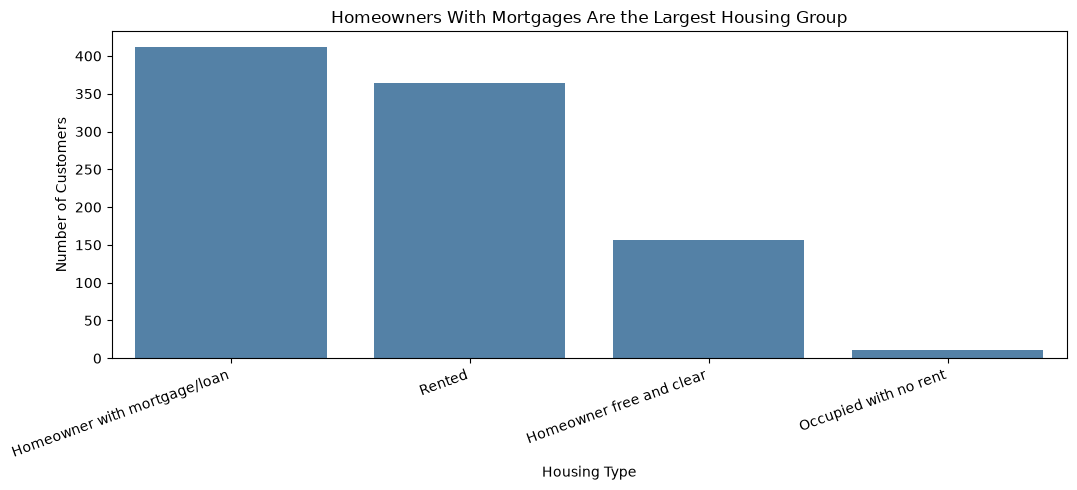

In [3]:
counts = clean_df["housing.type"].value_counts()

plt.figure(figsize=(11, 5))

sns.barplot(
    x=counts.index,
    y=counts.values,
    color="steelblue"
)

plt.title("Homeowners With Mortgages Are the Largest Housing Group")
plt.xlabel("Housing Type")
plt.ylabel("Number of Customers")
plt.xticks(rotation=20, ha="right")
plt.ylim(bottom=0)
plt.tight_layout()
plt.show()

What I did was remove 56 rows with missing housing information from the original 1,000 customers, which left 944 valid rows for the bar chart.

GitHub Repository:
https://github.com/leonhong2007/cs82a-portfolio/tree/main/module5